In [1]:
import pandas as pd 

dataset = pd.read_csv(r"data\matching_dataset.csv")

dataset.head()

,item_name_from_request,matching_catalog_name
0,A4 printer paper,A4 paper
1,balloons,NaN
2,decorative washi tape,Decorative adhesive tape (washi tape)
3,A4 glossy paper,A4 glossy paper
4,streamers,Party streamers


In [2]:
from supply_chain_agents.embeddings import embed
from supply_chain_agents.config import catalog_items
import numpy as np

catalog_embeddings = embed(catalog_items)
thresholds = np.arange(0.5, 0.99, 0.001)
results = {threshold: {'fp': 0, 'acc': 0} for threshold in thresholds}


for idx, item_name in enumerate(dataset['item_name_from_request']):
    query_vec = embed(item_name)
    cos_sims = catalog_embeddings @ query_vec
    best_idx = int(np.argmax(cos_sims))
    for threshold in thresholds:
        matched_catalog_item = (
            catalog_items[best_idx]
            if cos_sims[best_idx] >= threshold
            else np.nan)
        target = dataset['matching_catalog_name'].iloc[idx]
        is_match = False
        if pd.isna(target):
            is_match = pd.isna(matched_catalog_item)
            if not is_match:
                results[threshold]['fp'] += 1      
        else:
            is_match = matched_catalog_item == dataset['matching_catalog_name'].iloc[idx]

        if is_match:
            results[threshold]['acc'] += 1
        if not pd.isna(matched_catalog_item) and not is_match:
            results[threshold]['fp'] += 1
            

df = (
    pd.DataFrame.from_dict(data=results, orient='index')
      .rename_axis('threshold')
      .sort_index()
)

df['acc'] = df['acc']/len(dataset)

c:\Users\a.krimi\.conda\envs\test-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\a.krimi\.conda\envs\test-env\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\a.krimi\.cache\huggingface\hub\models--alibaba-nlp-community--gte-large-en-v1.5. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. I

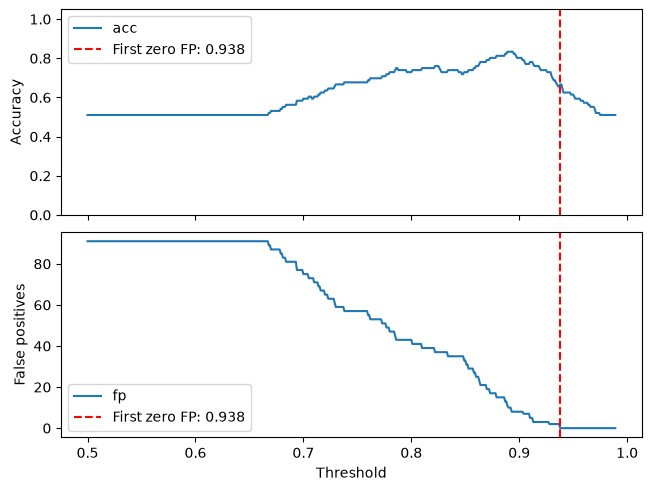

In [3]:
import matplotlib.pyplot as plt

fig, (ax_acc, ax_fp) = plt.subplots(2, 1, sharex=True, layout='constrained')
df['acc'].plot(ax=ax_acc, ylabel='Accuracy', ylim=(0, 1.05))
df['fp'].plot(ax=ax_fp, ylabel='False positives', xlabel='Threshold')


zero_fp = df.loc[df['fp'].eq(0)]

if not zero_fp.empty:
    t = zero_fp.index.min()
    for ax in (ax_acc, ax_fp):
        ax.axvline(t, color='red', linestyle='--', label=f'First zero FP: {t:.3f}')
        ax.legend()

plt.show()

In [1]:
from sentence_transformers import CrossEncoder

reranker = CrossEncoder("BAAI/bge-reranker-v2-m3")

query = "A4 glossy printer paper"

candidates = [
    "A4 glossy paper",
    "A4 matte paper",
    "A3 glossy paper",
]

pairs = [(query, candidate) for candidate in candidates]

scores = reranker.predict(pairs)

c:\Users\a.krimi\.conda\envs\test-env\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\a.krimi\.cache\huggingface\hub\models--BAAI--bge-reranker-v2-m3. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\a.krimi\.conda\envs\test-env\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning

In [ ]:
from supply_chain_agents.embeddings import embed
from supply_chain_agents.config import catalog_items
import numpy as np

catalog_embeddings = embed(catalog_items)
thresholds = np.arange(0.5, 0.99, 0.001)
results = {threshold: {'fp': 0, 'acc': 0} for threshold in thresholds}


for idx, item_name in enumerate(dataset['item_name_from_request']):
    query_vec = embed(item_name)
    cos_sims = catalog_embeddings @ query_vec
    for threshold in thresholds:
        cos_sims.sort(order=)
        matched_catalog_item = (
            catalog_items[best_idx]
            if cos_sims[best_idx] >= threshold
            else np.nan)
        target = dataset['matching_catalog_name'].iloc[idx]
        is_match = False
        if pd.isna(target):
            is_match = pd.isna(matched_catalog_item)
            if not is_match:
                results[threshold]['fp'] += 1      
        else:
            is_match = matched_catalog_item == dataset['matching_catalog_name'].iloc[idx]

        if is_match:
            results[threshold]['acc'] += 1
        if not pd.isna(matched_catalog_item) and not is_match:
            results[threshold]['fp'] += 1
            

df = (
    pd.DataFrame.from_dict(data=results, orient='index')
      .rename_axis('threshold')
      .sort_index()
)

df['acc'] = df['acc']/len(dataset)

[0.99986315 0.16063747 0.02594507]
